In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import * 
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {device}')

Using cpu


In [5]:
import requests
from io import BytesIO
import certifi

In [6]:
# 전처리
path = 'https://bit.ly/ds_boston_csv'
response = requests.get(path,verify=certifi.where(),timeout=15)
response.raise_for_status()
data = pd.read_csv(BytesIO(response.content))

# x, y 분할
target = 'medv'
features = ['lstat', 'ptratio', 'crim']
x = data.loc[:, features]
y= data.loc[:, target]

# xtrain, val 분할
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2, random_state=20)

# 스케일러 선언
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

In [7]:
# 텐서 변환 + Data Loader 생성 함수
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32) :
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)
    
    # TensorDataSet 생성
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    # DataLoader 생성
    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)
    return train_loader , x_val_tensor, y_val_tensor

In [8]:
# 넘파이 배열변환 - cpu 연산
y_train = y_train.values
y_val = y_val.values

In [9]:
# 데이터 로더 구성 by make_Dataset
train_loader, x_val_ts, y_val_ts = make_DataSet(x_train, x_val, y_train, y_val, 32)

In [10]:
# 모델 구조 설계
n_feature = x.shape[1]
model1= nn.Sequential(nn.Linear(n_feature, 1)).to(device)
loss_fn = nn.MSELoss()
optimizer = Adam(model1.parameters(), lr=0.01)
print(model1)

Sequential(
  (0): Linear(in_features=3, out_features=1, bias=True)
)


In [11]:
# 학습 함수 정의
def train(dataloader, model, loss_fn, optimizer, device):
    size= len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches
    return tr_loss.item()

In [12]:
# 검증 함수 정의
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [13]:
# 주기 100으로 학습
epochs = 100
tr_loss_list, vals_loss_list = [], [] # list로 저장하는 이유: 학습곡선
for t in range(epochs):
    tr_loss = train(train_loader, model1, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_ts, y_val_ts, model1, loss_fn, device)
    tr_loss_list.append(tr_loss)
    vals_loss_list.append(val_loss)
    print(f'Epoch {t+1}, train loss {tr_loss:4f}, val loss {val_loss:4f}')

Epoch 1, train loss 586.056580, val loss 507.373779
Epoch 2, train loss 579.498779, val loss 497.175690
Epoch 3, train loss 570.369995, val loss 487.128479
Epoch 4, train loss 560.234619, val loss 477.332764
Epoch 5, train loss 547.953064, val loss 467.679840
Epoch 6, train loss 535.815796, val loss 458.235596
Epoch 7, train loss 527.850037, val loss 449.006348
Epoch 8, train loss 520.818420, val loss 440.018829
Epoch 9, train loss 510.450165, val loss 431.140442
Epoch 10, train loss 502.227600, val loss 422.444153
Epoch 11, train loss 488.029816, val loss 414.026001
Epoch 12, train loss 482.283752, val loss 405.721558
Epoch 13, train loss 473.931824, val loss 397.617981
Epoch 14, train loss 473.480682, val loss 389.696472
Epoch 15, train loss 458.239136, val loss 381.924927
Epoch 16, train loss 447.243927, val loss 374.308838
Epoch 17, train loss 444.146118, val loss 366.879822
Epoch 18, train loss 435.241425, val loss 359.571869
Epoch 19, train loss 422.848602, val loss 352.582520
Ep

In [14]:
# 학습 곡선 함수
def dl_learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train_err', marker='.')
    plt.plot(epochs, val_loss_list, label= 'val_err', marker='.')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid()
    plt.show()

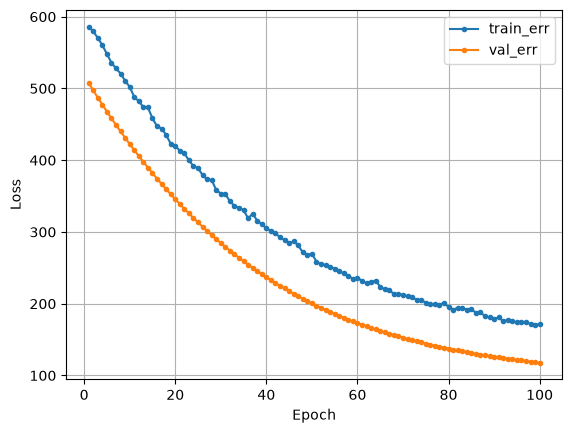

In [15]:
dl_learning_curve(tr_loss_list, vals_loss_list)

In [16]:
_, pred = evaluate(x_val_ts, y_val_ts, model1, loss_fn, device)
mae = mean_absolute_error(y_val_ts.numpy(), pred.numpy())
mape = mean_absolute_percentage_error(y_val_ts.numpy(), pred.numpy())
print('MAE(평균오차):', mae)
print('MAPE(평균오차율): ', mape)

MAE(평균오차): 7.482464790344238
MAPE(평균오차율):  0.3641910254955292
